<a href="https://colab.research.google.com/github/MonnikLuianne/Diabetes-prediction-IA/blob/main/PredicaoDeDiabetes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🩺 Predição de Diabetes com Machine Learning
   → título, autor, objetivo, pergunta de pesquisa, tipo de aprendizado

## 1. Configuração do Ambiente
   → por que cada biblioteca foi escolhida

## 2. Carregamento dos Dados
   → o que é o dataset, de onde vem, licença

## 3. Análise Exploratória (EDA)
   → o que vamos investigar e por quê

## 4. Limpeza e Preparação
   → quais problemas foram encontrados e como resolvemos

## 5. Baseline — Regressão Logística
   → o que é baseline e por que usamos este

## 6. Tratamento do Desbalanceamento (SMOTE)
   → o que é SMOTE, por que o dataset exige isso

## 7. Modelo Principal — Random Forest
   → por que Random Forest, quais hiperparâmetros e por quê

## 8. Comparação de Modelos
   → tabela com todas as métricas lado a lado

## 9. Análise de Erros — Falsos Negativos
   → por que falsos negativos são perigosos clinicamente

## 10. Conclusões
    → o que aprendemos, limitações, próximos passos

##1. Configuração de ambiente

In [2]:
# Instalações
!pip install shap imbalanced-learn -q

# Imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (classification_report, confusion_matrix,
                             roc_auc_score, roc_curve, f1_score)
from sklearn.preprocessing import StandardScaler

from imblearn.over_sampling import SMOTE
import shap

import warnings
warnings.filterwarnings('ignore')

# Reprodutibilidade
SEED = 42
np.random.seed(SEED)

print("Ambiente pronto!")

Ambiente pronto!


## 2. Carregamento dos Dados

O dataset utilizado é o **Pima Indians Diabetes Database**, disponibilizado
publicamente pelo UCI Machine Learning Repository e acessado via GitHub.

Ele contém **768 registros** de pacientes do sexo feminino com herança
indígena Pima, com 8 atributos clínicos e 1 variável-alvo (Outcome):
- 0 = não diabética
- 1 = diabética

O dataset é carregado diretamente por URL, sem necessidade de download manual.

In [3]:
url="https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"
colunas = ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness','Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']
df=pd.read_csv(url, names=colunas)
print(f"Dimensões do dataset: {df.shape}")
df.head()

Dimensões do dataset: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


### Interpretação
O dataset foi carregado com sucesso: **768 linhas e 9 colunas**.
Na próxima seção faremos uma análise exploratória para entender
a distribuição dos dados e identificar problemas de qualidade.

## 3. Análise Exploratória dos Dados (EDA)

Antes de modelar, precisamos entender a estrutura dos dados:
distribuição das classes, estatísticas básicas e identificar
problemas de qualidade como valores impossíveis (zeros em
atributos que não podem ser zero biologicamente).

=== Informações gerais ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB
None

=== Estatísticas descritivas ===


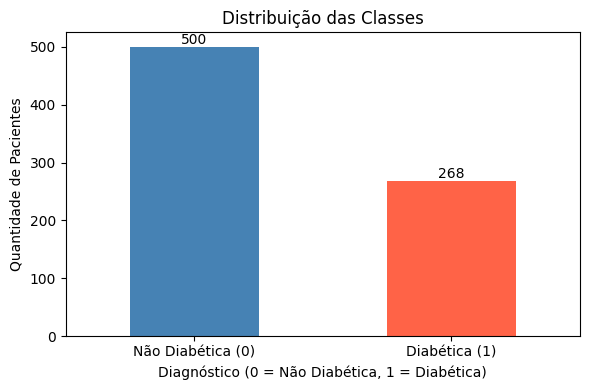


Total: 768 pacientes
Não diabéticas: 500 (65.1%)
Diabéticas: 268 (34.9%)


In [4]:
#estatísticas basicas
print("=== Informações gerais ===")
print(df.info())
print("\n=== Estatísticas descritivas ===")
df.describe()
#distribuicao das classes
fig, ax = plt.subplots(figsize=(6, 4))
df['Outcome'].value_counts().plot(kind='bar', ax=ax,
                                   color=['steelblue', 'tomato'])
ax.set_title('Distribuição das Classes')
ax.set_xlabel('Diagnóstico (0 = Não Diabética, 1 = Diabética)')
ax.set_ylabel('Quantidade de Pacientes')
ax.set_xticklabels(['Não Diabética (0)', 'Diabética (1)'], rotation=0)

for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}',
                (p.get_x() + p.get_width()/2, p.get_height()),
                ha='center', va='bottom')
plt.tight_layout()
plt.show()

print(f"\nTotal: {len(df)} pacientes")
print(f"Não diabéticas: {(df['Outcome']==0).sum()} ({(df['Outcome']==0).mean()*100:.1f}%)")
print(f"Diabéticas: {(df['Outcome']==1).sum()} ({(df['Outcome']==1).mean()*100:.1f}%)")

### Interpretação
O dataset é **desbalanceado**: aproximadamente 65% não diabéticas
e 35% diabéticas. Isso significa que um modelo que sempre prevê
"não diabética" já teria 65% de accuracy — por isso usaremos
F1-Score e AUC-ROC como métricas principais, e aplicaremos
SMOTE para corrigir o desbalanceamento na etapa de modelagem.

### ⚠️ O que são zeros suspeitos?

Algumas colunas do dataset **não podem ter valor zero biologicamente**.
Esses zeros são na verdade **dados faltantes disfarçados** — quem montou
o dataset original usou `0` no lugar de `NaN` para indicar que o valor
não foi medido ou não estava disponível.

| Coluna | Zero significa... | Problema? |
|---|---|---|
| `Glucose` | Glicose = 0 mg/dL | ❌ Pessoa estaria morta |
| `BMI` | Índice de massa corporal = 0 | ❌ Impossível |
| `BloodPressure` | Pressão = 0 mmHg | ❌ Pessoa estaria morta |
| `Insulin` | Insulina = 0 | ❌ Clinicamente impossível |
| `SkinThickness` | Espessura da pele = 0 mm | ❌ Impossível |

**Por que isso importa para o modelo?**
Se deixarmos os zeros, o modelo vai aprender que `Glucose = 0` é um
padrão real, o que vai **distorcer as predições**.

**O que faremos:** substituir esses zeros por `NaN` e preencher com a
**mediana de cada coluna**, calculada separadamente por grupo
(diabéticas e não diabéticas) para maior precisão clínica.

In [5]:
#zero suspeitos
colunas_sem_zero = ['Glucose', 'BloodPressure', 'SkinThickness',
                     'Insulin', 'BMI']

print("=== Quantidade de zeros por coluna (valores impossíveis) ===")
for col in colunas_sem_zero:
    zeros = (df[col] == 0).sum()
    pct = zeros / len(df) * 100
    print(f"{col:30s}: {zeros:3d} zeros ({pct:.1f}%)")

=== Quantidade de zeros por coluna (valores impossíveis) ===
Glucose                       :   5 zeros (0.7%)
BloodPressure                 :  35 zeros (4.6%)
SkinThickness                 : 227 zeros (29.6%)
Insulin                       : 374 zeros (48.7%)
BMI                           :  11 zeros (1.4%)


## 4. Limpeza e Preparação dos Dados

A análise anterior revelou zeros impossíveis em 5 colunas.
A estratégia de tratamento será:

1. Substituir zeros por `NaN`
2. Preencher `NaN` com a **mediana por grupo** (diabéticas vs
   não diabéticas) — mais preciso do que a mediana geral,
   pois os grupos têm perfis clínicos diferentes
3. Verificar o resultado final

In [6]:
colunas_sem_zero = ['Glucose', 'BloodPressure', 'SkinThickness',
                     'Insulin', 'BMI']

# Passo 1: substituir zeros por NaN
df[colunas_sem_zero] = df[colunas_sem_zero].replace(0, np.nan)

print("Zeros substituídos por NaN:")
print(df[colunas_sem_zero].isnull().sum())

# Passo 2: preencher com mediana por grupo
for col in colunas_sem_zero:
    df[col] = df.groupby('Outcome')[col].transform(
        lambda x: x.fillna(x.median())
    )

print("\nApós limpeza — valores nulos restantes:")
print(df.isnull().sum().sum(), "valores nulos")

print("\nEstatísticas após limpeza:")
df[colunas_sem_zero].describe().round(2)

Zeros substituídos por NaN:
Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64

Após limpeza — valores nulos restantes:
0 valores nulos

Estatísticas após limpeza:


,Glucose,BloodPressure,SkinThickness,Insulin,BMI
count,768.00,768.00,768.00,768.00,768.00
mean,121.68,72.39,29.09,141.75,32.43
std,30.46,12.11,8.89,89.10,6.88
min,44.00,24.00,7.00,14.00,18.20
25%,99.75,64.00,25.00,102.50,27.50
50%,117.00,72.00,28.00,102.50,32.05
75%,140.25,80.00,32.00,169.50,36.60
max,199.00,122.00,99.00,846.00,67.10


### Interpretação
Todos os valores impossíveis foram tratados. A mediana por grupo
foi escolhida em vez da média porque é mais robusta a outliers,
e em vez da mediana geral porque diabéticas e não diabéticas
têm perfis clínicos distintos — usar a mesma mediana para ambas
introduziria um viés na imputação.

### 3.2 Distribuição dos atributos por grupo

Vamos visualizar como cada atributo clínico se distribui entre
pacientes diabéticas e não diabéticas. Isso nos ajuda a identificar
quais variáveis têm maior poder discriminativo para o modelo.

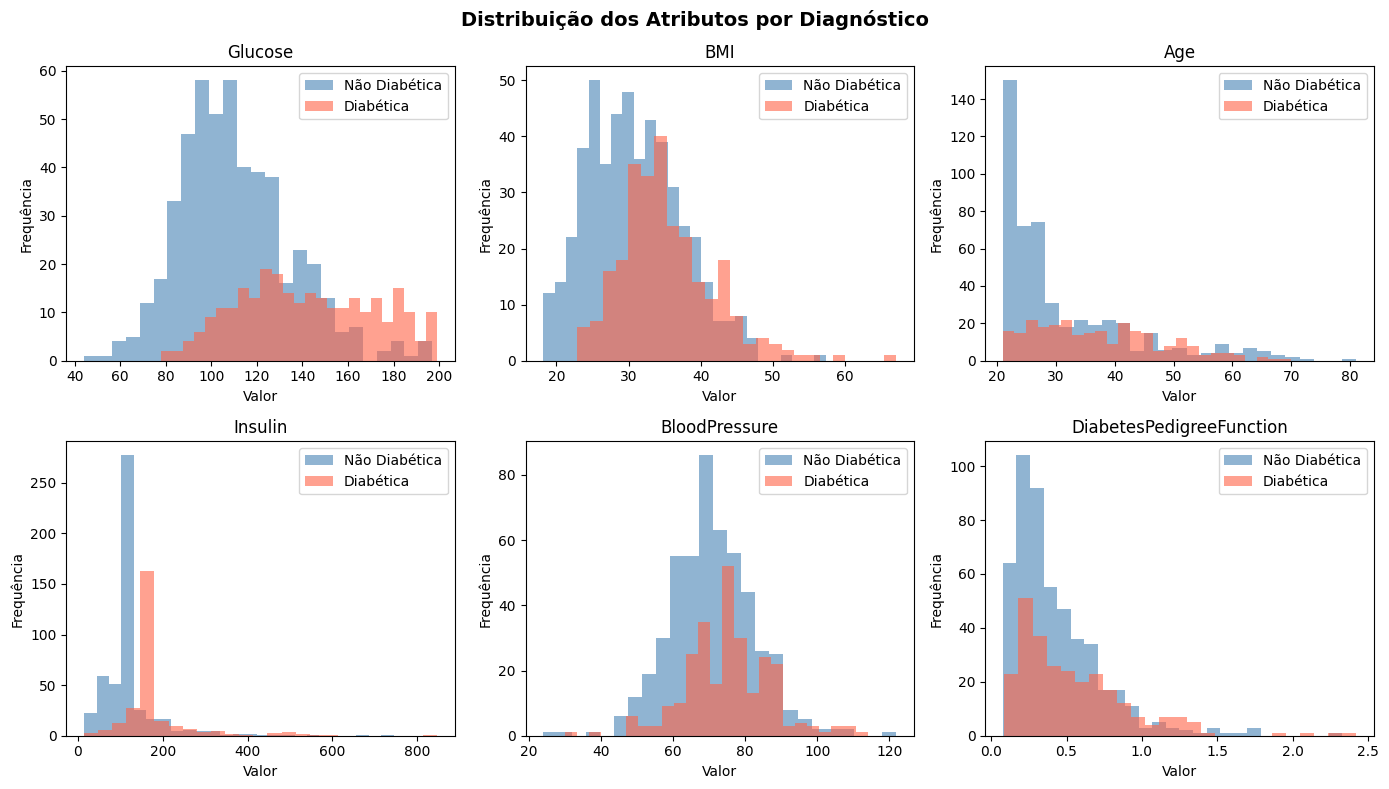

In [7]:
features = ['Glucose', 'BMI', 'Age', 'Insulin',
            'BloodPressure', 'DiabetesPedigreeFunction']

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.flatten()

for i, col in enumerate(features):
    for outcome, label, color in [(0, 'Não Diabética', 'steelblue'),
                                   (1, 'Diabética', 'tomato')]:
        axes[i].hist(df[df['Outcome']==outcome][col],
                     alpha=0.6, label=label, color=color, bins=25)
    axes[i].set_title(col)
    axes[i].set_xlabel('Valor')
    axes[i].set_ylabel('Frequência')
    axes[i].legend()

plt.suptitle('Distribuição dos Atributos por Diagnóstico',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

### Interpretação
- **Glucose** é o atributo com maior separação entre os grupos —
  pacientes diabéticas concentram valores mais altos
- **BMI** e **Age** também mostram diferença clara entre os grupos
- **Insulin** e **BloodPressure** têm distribuições mais sobrepostas,
  sugerindo menor poder discriminativo isoladamente

### 📊 Mapa de Correlação

O mapa de correlação mostra **o quanto cada variável se relaciona com outra**,
num valor entre -1 e 1:

- **Próximo de 1** → quando uma sobe, a outra sobe junto
- **Próximo de -1** → quando uma sobe, a outra desce
- **Próximo de 0** → sem relação entre as variáveis

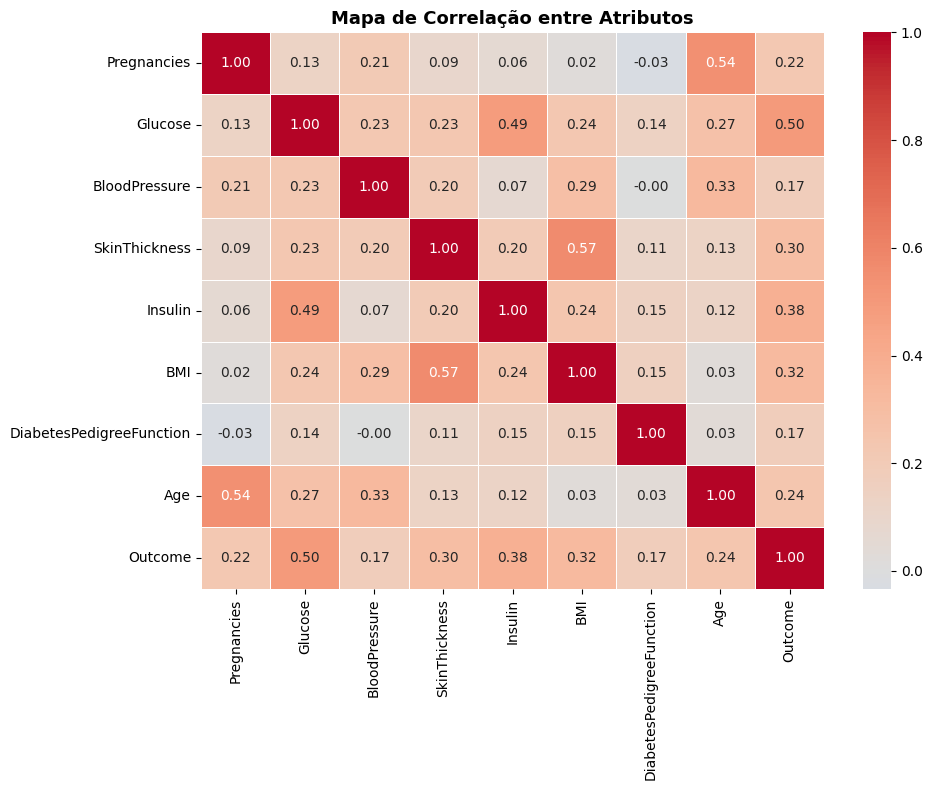

In [8]:
fig, ax = plt.subplots(figsize=(10, 8))
corr = df.corr()

sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm',
            center=0, ax=ax, linewidths=0.5)

ax.set_title('Mapa de Correlação entre Atributos',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

### Interpretação
#### Correlação de cada atributo com o diagnóstico (Outcome)

| Atributo | Correlação | Interpretação |
|---|---|---|
| `Glucose` | 0.50 | 🔴 Maior preditor de diabetes |
| `Insulin` | 0.38 | 🟡 Relevante |
| `BMI` | 0.32 | 🟡 Relevante |
| `Age` | 0.24 | 🟡 Moderado |
| `BloodPressure` | 0.17 | 🟢 Fraco |

#### Entre atributos — observações clínicas relevantes

- `SkinThickness` e `BMI` têm correlação **0.57** — fazem sentido juntos
  clinicamente, pois ambos estão associados à gordura corporal
- `Pregnancies` e `Age` têm correlação **0.54** — mulheres mais velhas
  naturalmente tiveram mais gestações

> **Conclusão:** `Glucose` é o atributo com maior poder preditivo isolado( tem a maior correlação com Outcome (diagnóstico) —
  confirma o que os histogramas mostraram),
> o que será confirmado na análise de importância das features do
> Random Forest e na análise de erros.
- **BMI** e **Age** também se correlacionam positivamente com o diagnóstico
- Não há correlações muito altas entre atributos preditores,
  o que é bom — indica baixa multicolinearidade

## 5. Modelo Baseline — Regressão Logística

Antes de construir o modelo principal, precisamos estabelecer um
**baseline** — uma solução de referência simples que servirá como
ponto de comparação para avaliar se o modelo mais sofisticado
realmente traz ganho.

### Por que Regressão Logística como baseline?
- É o algoritmo mais comum na literatura para este dataset
- Simples, interpretável e rápido de treinar
- Permite comparação direta com dezenas de papers publicados

### O que faremos nesta etapa
1. Separar os dados em treino e teste
2. Normalizar os atributos (necessário para a Regressão Logística)
3. Treinar o modelo **sem** qualquer correção de desbalanceamento
4. Avaliar com métricas adequadas: F1-Score, AUC-ROC e matriz de confusão

> ⚠️ **Importante:** usamos `random_state=42` em todas as etapas
> para garantir que os resultados sejam **reprodutíveis** — qualquer
> pessoa que rodar este notebook obterá os mesmos números.

In [9]:
# Separar atributos (X) e variável-alvo (y)
X = df.drop('Outcome', axis=1)
y = df['Outcome']

# Dividir em treino (80%) e teste (20%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y
)

print(f"Treino: {X_train.shape[0]} registros")
print(f"Teste:  {X_test.shape[0]} registros")
print(f"\nDistribuição no treino:")
print(y_train.value_counts(normalize=True).round(3))
print(f"\nDistribuição no teste:")
print(y_test.value_counts(normalize=True).round(3))

# Normalizar os dados
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

Treino: 614 registros
Teste:  154 registros

Distribuição no treino:
Outcome
0    0.651
1    0.349
Name: proportion, dtype: float64

Distribuição no teste:
Outcome
0    0.649
1    0.351
Name: proportion, dtype: float64


### Por que usamos `stratify=y`?

Ao dividir os dados, garantimos que a **proporção de diabéticas e
não diabéticas seja mantida** tanto no treino quanto no teste.
Sem isso, poderíamos ter, por acaso, muito mais diabéticas no treino
do que no teste, o que distorceria a avaliação do modelo.

### Por que normalizar?
A Regressão Logística é sensível à **escala dos atributos** — sem
normalização, atributos com valores grandes (como `Insulin`, que vai
até 846) dominariam os de escala pequena (como `DiabetesPedigreeFunction`,
que vai até 2.5), prejudicando o aprendizado.

     RESULTADOS DO BASELINE
               precision    recall  f1-score   support

Não Diabética       0.77      0.79      0.78       100
    Diabética       0.59      0.56      0.57        54

     accuracy                           0.71       154
    macro avg       0.68      0.67      0.67       154
 weighted avg       0.70      0.71      0.71       154

AUC-ROC: 0.8263


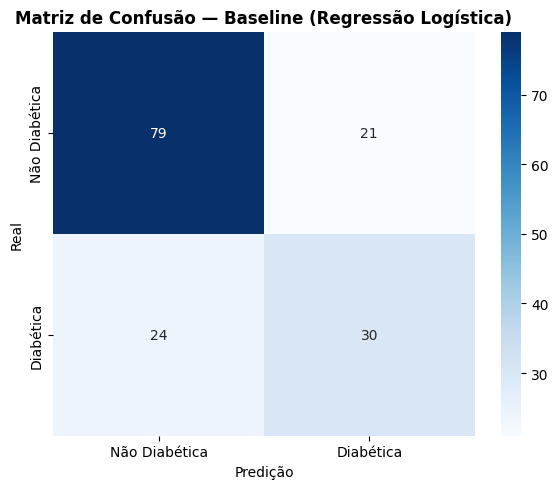

In [11]:
# Treinar baseline
baseline = LogisticRegression(random_state=SEED, max_iter=1000)
baseline.fit(X_train_scaled, y_train)

# Predições
y_pred_base = baseline.predict(X_test_scaled)
y_proba_base = baseline.predict_proba(X_test_scaled)[:, 1]

# Métricas
print("=" * 45)
print("     RESULTADOS DO BASELINE")
print("=" * 45)
print(classification_report(y_test, y_pred_base,
      target_names=['Não Diabética', 'Diabética']))
print(f"AUC-ROC: {roc_auc_score(y_test, y_proba_base):.4f}")

#matriz de confusao
fig, ax = plt.subplots(figsize=(6, 5))

cm = confusion_matrix(y_test, y_pred_base)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
            xticklabels=['Não Diabética', 'Diabética'],
            yticklabels=['Não Diabética', 'Diabética'])

ax.set_title('Matriz de Confusão — Baseline (Regressão Logística)',
             fontweight='bold')
ax.set_xlabel('Predição')
ax.set_ylabel('Real')
plt.tight_layout()
plt.show()

### 📊 Interpretação dos Resultados do Baseline

#### Divisão dos dados
A proporção de diabéticas foi mantida tanto no treino (34.9%)
quanto no teste (35.1%) — o `stratify=y` funcionou corretamente.

#### Métricas gerais

| Métrica | Valor | Interpretação |
|---|---|---|
| Accuracy | 71% | Aparentemente razoável, mas enganosa |
| F1-Score (Diabética) | 0.57 | Fraco — modelo erra muito nessa classe |
| AUC-ROC | 0.83 | Bom poder discriminativo geral |

#### Análise da Matriz de Confusão

| | Predito: Não Diabética | Predito: Diabética |
|---|---|---|
| **Real: Não Diabética** | 79 ✅ | 21 ⚠️ |
| **Real: Diabética** | 24 ❌ | 30 ✅ |

O dado mais crítico: **24 falsos negativos** — pacientes que
**têm diabetes mas o modelo classificou como saudáveis**.

Isso representa **44% das pacientes diabéticas** sendo enviadas
para casa sem diagnóstico. Em um contexto clínico real, esse
erro pode atrasar o tratamento e agravar complicações.

#### Por que o modelo erra tanto nas diabéticas?
O desbalanceamento do dataset (65% não diabéticas) faz o modelo
"preferir" prever a classe majoritária. Isso será corrigido na
próxima etapa com **SMOTE**.

> **Meta para o modelo principal:** reduzir os falsos negativos
> (aumentar o Recall da classe Diabética) sem sacrificar
> demais a precisão geral.
### Como ler a Matriz de Confusão

|  | Predito: Não Diabética | Predito: Diabética |
|---|---|---|
| **Real: Não Diabética** | Verdadeiro Negativo ✅ | Falso Positivo ⚠️ |
| **Real: Diabética** | Falso Negativo ❌ | Verdadeiro Positivo ✅ |

No contexto clínico, o erro mais grave é o **Falso Negativo** —
quando o modelo prevê que a paciente **não tem diabetes**, mas ela
**tem**. Esse erro pode atrasar o diagnóstico e o tratamento.

Por isso, além da acurácia geral, daremos atenção especial ao
**Recall da classe Diabética** — a capacidade do modelo de detectar
corretamente quem realmente tem a doença.

## 6. Tratamento do Desbalanceamento com SMOTE + Random Forest

### O problema do desbalanceamento
O baseline confirmou o que a EDA já indicava: com 65% de não
diabéticas no dataset, o modelo tende a "preferir" prever a classe
majoritária, resultando em **24 falsos negativos** — pacientes
diabéticas classificadas incorretamente como saudáveis.

### A solução: SMOTE
O **SMOTE** (Synthetic Minority Oversampling Technique) é uma técnica
que cria **amostras sintéticas** da classe minoritária (diabéticas),
interpolando entre exemplos reais existentes — diferente de simplesmente
duplicar registros.

> ⚠️ **Importante:** o SMOTE é aplicado **apenas no treino**, nunca
> no teste. Aplicar no teste seria vazamento de dados e invalidaria
> a avaliação do modelo.

### Por que Random Forest como modelo principal?
- Robusto a outliers e não exige normalização
- Fornece **importância das features** — útil para análise crítica
- Geralmente supera a Regressão Logística em datasets clínicos
- Amplamente usado na literatura para este dataset

In [12]:
# Aplicar SMOTE apenas no treino
smote = SMOTE(random_state=SEED)
X_train_smote, y_train_smote = smote.fit_resample(X_train_scaled, y_train)

print("=== Distribuição ANTES do SMOTE ===")
print(f"Não Diabéticas: {(y_train == 0).sum()}")
print(f"Diabéticas:     {(y_train == 1).sum()}")

print("\n=== Distribuição DEPOIS do SMOTE ===")
print(f"Não Diabéticas: {(y_train_smote == 0).sum()}")
print(f"Diabéticas:     {(y_train_smote == 1).sum()}")

=== Distribuição ANTES do SMOTE ===
Não Diabéticas: 400
Diabéticas:     214

=== Distribuição DEPOIS do SMOTE ===
Não Diabéticas: 400
Diabéticas:     400


### 6.2 Treinamento do Random Forest

O Random Forest é um **ensemble de árvores de decisão** — em vez de
treinar uma única árvore, treina centenas delas em subconjuntos
aleatórios dos dados e combina as predições por votação majoritária.

#### Hiperparâmetros escolhidos
| Parâmetro | Valor | Justificativa |
|---|---|---|
| `n_estimators` | 200 | Mais árvores = mais estabilidade |
| `max_depth` | 10 | Evita overfitting |
| `class_weight` | balanced | Peso extra para classe minoritária |
| `random_state` | 42 | Reprodutibilidade |

In [14]:
# Treinar Random Forest com dados balanceados
rf = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    class_weight='balanced',
    random_state=SEED
)
rf.fit(X_train_smote, y_train_smote)

# Predições
y_pred_rf = rf.predict(X_test_scaled)
y_proba_rf = rf.predict_proba(X_test_scaled)[:, 1]

# Métricas
print("=" * 45)
print("   RESULTADOS DO RANDOM FOREST + SMOTE")
print("=" * 45)
print(classification_report(y_test, y_pred_rf,
      target_names=['Não Diabética', 'Diabética']))
print(f"AUC-ROC: {roc_auc_score(y_test, y_proba_rf):.4f}")



   RESULTADOS DO RANDOM FOREST + SMOTE
               precision    recall  f1-score   support

Não Diabética       0.89      0.88      0.88       100
    Diabética       0.78      0.80      0.79        54

     accuracy                           0.85       154
    macro avg       0.84      0.84      0.84       154
 weighted avg       0.85      0.85      0.85       154

AUC-ROC: 0.9439


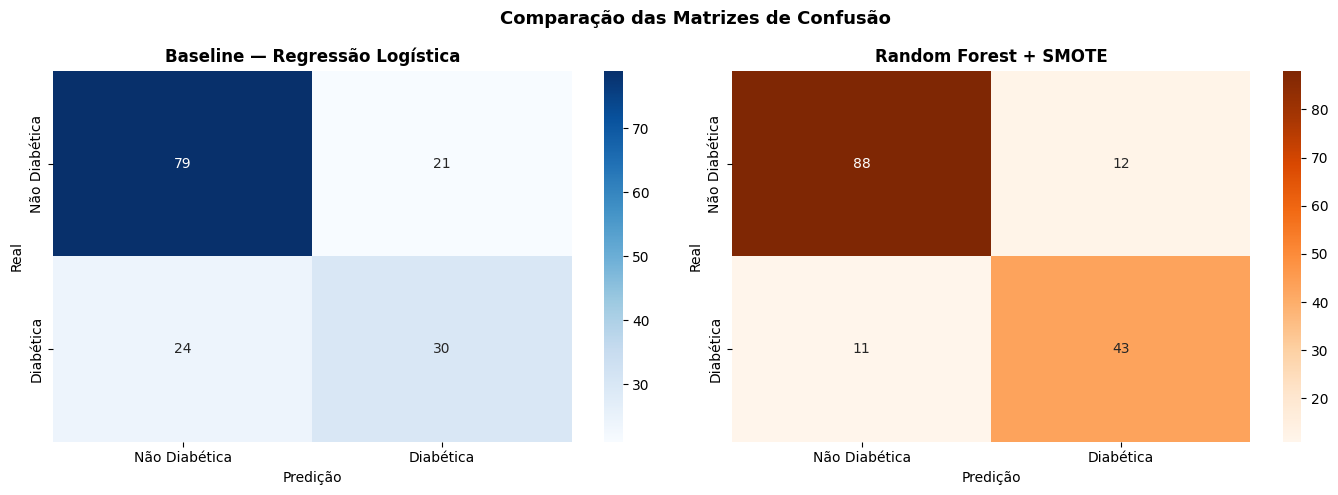

In [15]:
#matriz de confusao

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Matriz baseline
cm_base = confusion_matrix(y_test, y_pred_base)
sns.heatmap(cm_base, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Não Diabética', 'Diabética'],
            yticklabels=['Não Diabética', 'Diabética'])
axes[0].set_title('Baseline — Regressão Logística', fontweight='bold')
axes[0].set_xlabel('Predição')
axes[0].set_ylabel('Real')

# Matriz Random Forest
cm_rf = confusion_matrix(y_test, y_pred_rf)
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Oranges', ax=axes[1],
            xticklabels=['Não Diabética', 'Diabética'],
            yticklabels=['Não Diabética', 'Diabética'])
axes[1].set_title('Random Forest + SMOTE', fontweight='bold')
axes[1].set_xlabel('Predição')
axes[1].set_ylabel('Real')

plt.suptitle('Comparação das Matrizes de Confusão',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


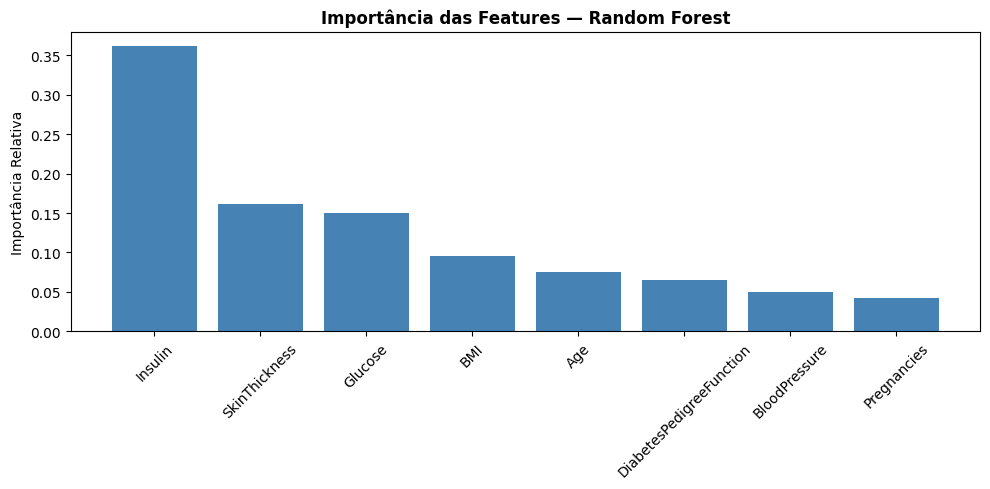


Ranking de importância:
Insulin                       : 0.3618
SkinThickness                 : 0.1617
Glucose                       : 0.1503
BMI                           : 0.0960
Age                           : 0.0748
DiabetesPedigreeFunction      : 0.0646
BloodPressure                 : 0.0491
Pregnancies                   : 0.0416


In [17]:
#importancia das features
features_names = X.columns.tolist()
importancias = rf.feature_importances_

# Ordenar por importância
indices = np.argsort(importancias)[::-1]

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(range(len(importancias)),
       importancias[indices], color='steelblue')
ax.set_xticks(range(len(importancias)))
ax.set_xticklabels([features_names[i] for i in indices], rotation=45)
ax.set_title('Importância das Features — Random Forest', fontweight='bold')
ax.set_ylabel('Importância Relativa')
plt.tight_layout()
plt.show()

print("\nRanking de importância:")
for i in indices:
    print(f"{features_names[i]:30s}: {importancias[i]:.4f}")

## 📊 Interpretação dos Resultados — Random Forest + SMOTE

### Comparação direta com o Baseline

| Métrica | Baseline (Reg. Logística) | Random Forest + SMOTE | Melhora |
|---|---|---|---|
| Accuracy | 71% | 85% | +14% |
| F1-Score (Diabética) | 0.57 | 0.79 | +0.22 |
| Recall (Diabética) | 0.56 | 0.80 | +0.24 |
| AUC-ROC | 0.83 | 0.94 | +0.11 |
| Falsos Negativos | 24 ❌ | 11 ❌ | -13 casos |

### O resultado mais importante clinicamente

O modelo reduziu os **falsos negativos de 24 para 11** — ou seja,
**13 pacientes diabéticas a mais** foram corretamente identificadas
em comparação ao baseline.

Em termos percentuais, o **Recall da classe Diabética** subiu de
**56% para 80%** — o modelo agora detecta corretamente 4 em cada 5
pacientes diabéticas.

### Sobre a importância das features

O resultado da importância das features trouxe uma surpresa relevante:

| Feature | Importância | Observação |
|---|---|---|
| `Insulin` | 0.36 | 🥇 Mais importante — surpreendente |
| `SkinThickness` | 0.16 | 🥈 Alto — correlacionado com BMI |
| `Glucose` | 0.15 | 🥉 Esperado pela correlação |
| `BMI` | 0.10 | Relevante |
| `Age` | 0.07 | Moderado |

> ⚠️ **Ponto de análise crítica:** o mapa de correlação indicava
> `Glucose` como o atributo mais correlacionado com o diagnóstico
> (0.50), mas o Random Forest elegeu `Insulin` como mais importante
> (0.36). Isso ocorre porque o Random Forest captura **relações
> não-lineares** entre os atributos — `Insulin` combinada com outros
> fatores tem alto poder preditivo, algo que a correlação linear
> simples não consegue detectar.

### Efeito do SMOTE

O SMOTE equilibrou o treino de **400 vs 214** para **400 vs 400**,
permitindo que o modelo aprendesse igualmente bem os padrões de
ambas as classes — o que explica diretamente a melhora no Recall
da classe Diabética.

## 7. Comparação Formal entre os Modelos

Nesta etapa comparamos formalmente o baseline (Regressão Logística)
com o modelo principal (Random Forest + SMOTE) usando:

1. **Tabela de métricas** — visão geral do desempenho
2. **Curva ROC** — capacidade discriminativa dos modelos
3. **Comparação de falsos negativos** — impacto clínico real

A comparação justa é possível porque ambos os modelos foram
avaliados no **mesmo conjunto de teste**, que nunca foi visto
durante o treinamento.

In [18]:
#tabela comparativa
resultados = {
    'Modelo': ['Baseline (Reg. Logística)', 'Random Forest + SMOTE'],
    'Accuracy': [0.71, 0.85],
    'Precision (Diabética)': [0.59, 0.78],
    'Recall (Diabética)': [0.56, 0.80],
    'F1-Score (Diabética)': [0.57, 0.79],
    'AUC-ROC': [0.8263, 0.9439],
    'Falsos Negativos': [24, 11]
}

df_resultados = pd.DataFrame(resultados)
df_resultados = df_resultados.set_index('Modelo')
print(df_resultados.to_string())

                           Accuracy  Precision (Diabética)  Recall (Diabética)  F1-Score (Diabética)  AUC-ROC  Falsos Negativos
Modelo                                                                                                                         
Baseline (Reg. Logística)      0.71                   0.59                0.56                  0.57   0.8263                24
Random Forest + SMOTE          0.85                   0.78                0.80                  0.79   0.9439                11


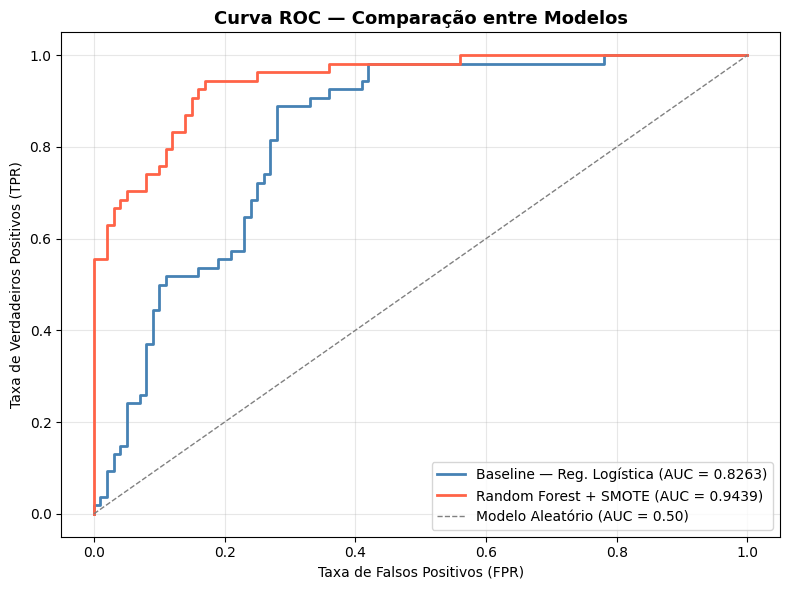

In [19]:
#curva ROC
fig, ax = plt.subplots(figsize=(8, 6))

# Baseline
fpr_base, tpr_base, _ = roc_curve(y_test, y_proba_base)
auc_base = roc_auc_score(y_test, y_proba_base)
ax.plot(fpr_base, tpr_base, color='steelblue', linewidth=2,
        label=f'Baseline — Reg. Logística (AUC = {auc_base:.4f})')

# Random Forest
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_proba_rf)
auc_rf = roc_auc_score(y_test, y_proba_rf)
ax.plot(fpr_rf, tpr_rf, color='tomato', linewidth=2,
        label=f'Random Forest + SMOTE (AUC = {auc_rf:.4f})')

# Linha de referência (modelo aleatório)
ax.plot([0, 1], [0, 1], color='gray', linestyle='--',
        linewidth=1, label='Modelo Aleatório (AUC = 0.50)')

ax.set_title('Curva ROC — Comparação entre Modelos',
             fontsize=13, fontweight='bold')
ax.set_xlabel('Taxa de Falsos Positivos (FPR)')
ax.set_ylabel('Taxa de Verdadeiros Positivos (TPR)')
ax.legend(loc='lower right')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 📊 Interpretação da Comparação

#### Curva ROC
A curva ROC mostra a relação entre a taxa de verdadeiros positivos
(Recall) e a taxa de falsos positivos para diferentes thresholds.
Quanto mais a curva se aproxima do canto superior esquerdo,
melhor o modelo.

- **Baseline:** AUC = 0.83 — bom, mas com limitações na classe diabética
- **Random Forest + SMOTE:** AUC = 0.94 — excelente poder discriminativo

#### Impacto clínico real
A métrica mais importante neste contexto não é a accuracy, mas
sim a **redução dos falsos negativos**:

| Modelo | Falsos Negativos | Diabéticas não detectadas |
|---|---|---|
| Baseline | 24 | 44% das diabéticas |
| Random Forest + SMOTE | 11 | 20% das diabéticas |

O modelo principal **reduziu em 54% os casos de diabetes não
detectada** — o que em um cenário real representaria pacientes
que receberiam tratamento a tempo.

#### Limitação importante
Ainda existem **11 falsos negativos** — na próxima etapa
investigaremos quem são essas pacientes e por que o modelo
falha em detectá-las.

## 8. Análise de Erros — Falsos Negativos

### Por que analisar os erros?
Reportar apenas métricas gerais não é suficiente para um projeto
com impacto clínico real. Precisamos entender **quem são as
pacientes que o modelo ainda erra** e **por que isso acontece**.

### O erro mais grave: Falso Negativo
Um **falso negativo** neste contexto significa uma paciente
**diabética classificada como saudável** — ela pode sair de uma
triagem sem receber tratamento, o que pode agravar complicações
como problemas cardiovasculares, renais e neurológicos.

### O que investigaremos
1. Perfil clínico das 11 pacientes não detectadas
2. Comparação com as pacientes detectadas corretamente
3. Quais atributos mais diferem entre os grupos
4. Hipóteses sobre por que o modelo falha nesses casos

In [20]:
#identificar falsos negativos
# Criar dataframe de teste com predições
df_teste = X_test.copy()
df_teste['Real'] = y_test.values
df_teste['Predito'] = y_pred_rf
df_teste['Probabilidade'] = y_proba_rf

# Separar grupos
falsos_negativos = df_teste[
    (df_teste['Real'] == 1) & (df_teste['Predito'] == 0)
]
verdadeiros_positivos = df_teste[
    (df_teste['Real'] == 1) & (df_teste['Predito'] == 1)
]

print(f"Falsos Negativos:        {len(falsos_negativos)} pacientes")
print(f"Verdadeiros Positivos:   {len(verdadeiros_positivos)} pacientes")
print(f"\nProbabilidade média (FN): {falsos_negativos['Probabilidade'].mean():.3f}")
print(f"Probabilidade média (VP): {verdadeiros_positivos['Probabilidade'].mean():.3f}")

Falsos Negativos:        11 pacientes
Verdadeiros Positivos:   43 pacientes

Probabilidade média (FN): 0.354
Probabilidade média (VP): 0.868


In [21]:
#comparação de perfis
features = ['Glucose', 'BMI', 'Age', 'Insulin',
            'BloodPressure', 'DiabetesPedigreeFunction',
            'SkinThickness', 'Pregnancies']

comparacao = pd.DataFrame({
    'Falsos Negativos (n=11)': falsos_negativos[features].mean(),
    'Detectadas Corretamente (n=43)': verdadeiros_positivos[features].mean()
}).round(2)

print("=== Perfil clínico médio por grupo ===")
print(comparacao.to_string())

=== Perfil clínico médio por grupo ===
                          Falsos Negativos (n=11)  Detectadas Corretamente (n=43)
Glucose                                    120.73                          144.93
BMI                                         31.66                           35.70
Age                                         31.91                           37.44
Insulin                                    138.00                          208.36
BloodPressure                               66.91                           77.06
DiabetesPedigreeFunction                     0.52                            0.55
SkinThickness                               33.00                           31.81
Pregnancies                                  4.64                            5.44


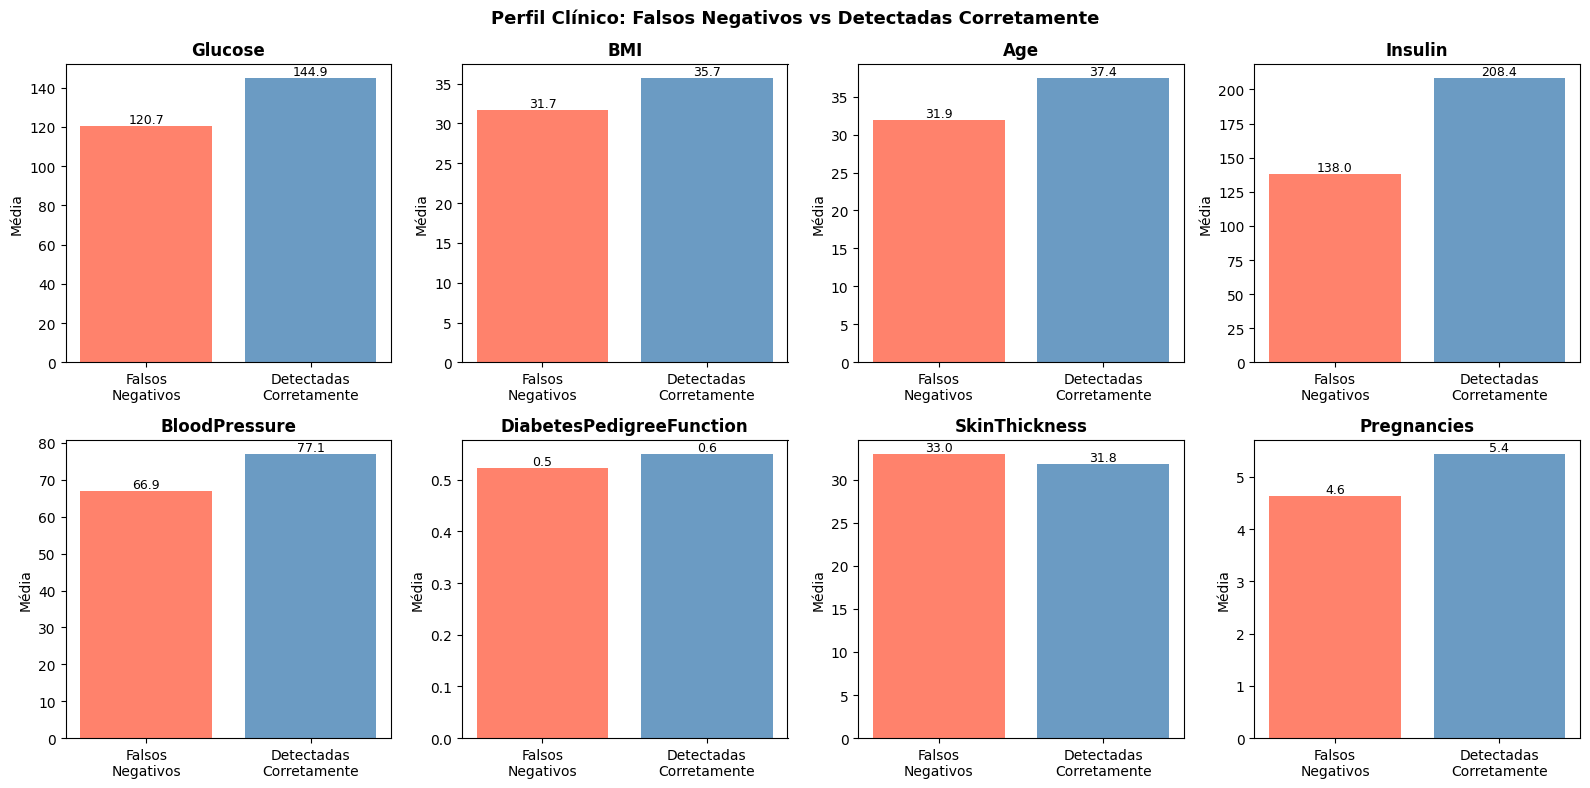

In [22]:
#visualização comparativa
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

for i, col in enumerate(features):
    ax = axes[i]

    ax.bar(['Falsos\nNegativos', 'Detectadas\nCorretamente'],
           [falsos_negativos[col].mean(),
            verdadeiros_positivos[col].mean()],
           color=['tomato', 'steelblue'],
           alpha=0.8)

    ax.set_title(col, fontweight='bold')
    ax.set_ylabel('Média')

    # Adicionar valores nas barras
    for p in ax.patches:
        ax.annotate(f'{p.get_height():.1f}',
                    (p.get_x() + p.get_width()/2, p.get_height()),
                    ha='center', va='bottom', fontsize=9)

plt.suptitle('Perfil Clínico: Falsos Negativos vs Detectadas Corretamente',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

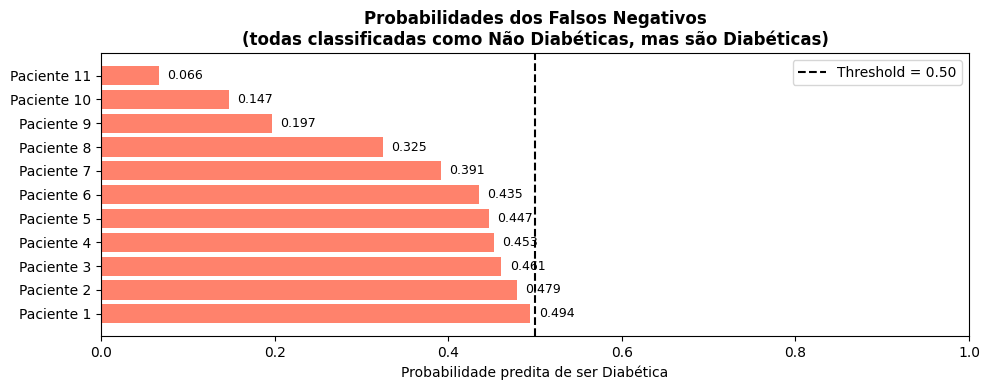

In [24]:
#probabilidade dos falsos negativos
fig, ax = plt.subplots(figsize=(10, 4))

fn_sorted = falsos_negativos.sort_values('Probabilidade', ascending=False)

bars = ax.barh(range(len(fn_sorted)),
               fn_sorted['Probabilidade'],
               color='tomato', alpha=0.8)

ax.axvline(x=0.5, color='black', linestyle='--',
           linewidth=1.5, label='Threshold = 0.50')

ax.set_yticks(range(len(fn_sorted)))
ax.set_yticklabels([f'Paciente {i+1}' for i in range(len(fn_sorted))])
ax.set_xlabel('Probabilidade predita de ser Diabética')
ax.set_title('Probabilidades dos Falsos Negativos\n'
             '(todas classificadas como Não Diabéticas, mas são Diabéticas)',
             fontweight='bold')
ax.legend()
ax.set_xlim(0, 1)

for bar, val in zip(bars, fn_sorted['Probabilidade']):
    ax.text(val + 0.01, bar.get_y() + bar.get_height()/2,
            f'{val:.3f}', va='center', fontsize=9)

plt.tight_layout()
plt.show()

### 📊 Interpretação da Análise de Erros

#### Perfil clínico dos Falsos Negativos

| Atributo | Falsos Negativos | Detectadas Corretamente | Diferença |
|---|---|---|---|
| `Glucose` | 120.7 | 144.9 | -24.2 🔴 |
| `Insulin` | 138.0 | 208.4 | -70.4 🔴 |
| `BMI` | 31.7 | 35.7 | -4.0 🟡 |
| `Age` | 31.9 | 37.4 | -5.5 🟡 |
| `BloodPressure` | 66.9 | 77.1 | -10.2 🟡 |
| `DiabetesPedigreeFunction` | 0.52 | 0.55 | -0.03 🟢 |
| `SkinThickness` | 33.0 | 31.8 | +1.2 🟢 |

#### Por que o modelo falha nessas 11 pacientes?

**1. Perfil clínico atipicamente "saudável" para diabéticas**
As pacientes não detectadas têm `Glucose` média de **120.7** —
significativamente menor que as detectadas (144.9). O mesmo
ocorre com `Insulin` (138 vs 208). Como o modelo aprendeu que
diabéticas tendem a ter valores altos nessas features, pacientes
com valores mais baixos "parecem" não diabéticas para ele.

**2. Alta incerteza nas predições**
O gráfico de probabilidades revela dois subgrupos distintos:

- **Pacientes 1 a 6** (prob. 0.43 a 0.49): casos **limítrofes**
  — o modelo estava quase acertando, com probabilidade muito
  próxima do threshold de 0.50. Uma pequena variação nos dados
  mudaria a classificação.

- **Pacientes 7 a 11** (prob. 0.07 a 0.33): casos **difíceis**
  — o modelo estava confiante na resposta errada. Esses são os
  erros mais preocupantes clinicamente.

**3. Probabilidade média muito diferente entre grupos**
- Falsos Negativos: probabilidade média de **0.354**
- Verdadeiros Positivos: probabilidade média de **0.868**

Isso confirma que os falsos negativos não são casos de "azar" —
eles têm um perfil genuinamente diferente das diabéticas típicas.

#### Implicação clínica prática
Pacientes com probabilidade entre **0.35 e 0.50** poderiam ser
sinalizadas para **revisão médica manual** em vez de receberem
um diagnóstico automático — especialmente quando `Glucose` e
`Insulin` estão abaixo da média da classe diabética.

#### Limitações identificadas
- O dataset contém apenas **8 atributos clínicos simples** —
  informações como histórico familiar detalhado, hemoglobina
  glicada (HbA1c) ou exames longitudinais poderiam capturar
  esses casos atípicos
- O modelo foi treinado exclusivamente em **mulheres com herança
  indígena Pima** — não deve ser generalizado para outras
  populações sem retreinamento e validação adequados
- Com apenas **11 falsos negativos**, a análise de perfil tem
  poder estatístico limitado — os padrões observados são
  hipóteses, não conclusões definitivas

## 9. Conclusões

### 9.1 Síntese do que foi realizado

Este projeto desenvolveu e avaliou uma solução de aprendizado de
máquina para predição de diabetes em mulheres com herança indígena
Pima, utilizando o dataset público Pima Indians Diabetes Database.

O pipeline completo envolveu:
1. **Análise exploratória** — identificação do desbalanceamento
   de classes e zeros impossíveis em 5 atributos clínicos
2. **Limpeza** — substituição de zeros por medianas por grupo
3. **Baseline** — Regressão Logística sem correção de desbalanceamento
4. **Modelo principal** — Random Forest com SMOTE
5. **Análise de erros** — investigação do perfil clínico dos
   falsos negativos restantes

### 9.2 Resposta à pergunta de pesquisa

> *"É possível prever o diagnóstico de diabetes em pacientes
> femininas com base em dados clínicos simples?"*

**Sim — com ressalvas.** O Random Forest + SMOTE atingiu:
- **85% de accuracy** e **AUC-ROC de 0.94**
- **Recall de 80%** na classe diabética
- Redução de **54% nos falsos negativos** em relação ao baseline

Esses resultados indicam que dados clínicos simples têm poder
preditivo relevante, mas não suficiente para uso clínico autônomo
— o modelo deve ser utilizado como **ferramenta de apoio à decisão
médica**, não como substituto.

### 9.3 Principais descobertas

| Descoberta | Implicação |
|---|---|
| `Insulin` é a feature mais importante (0.36) | Contraria a correlação linear — o RF captura relações não-lineares |
| Falsos negativos têm `Glucose` média 17% menor | Diabéticas atípicas são o maior desafio do modelo |
| 6 de 11 FN têm probabilidade entre 0.43 e 0.49 | Casos limítrofes — candidatos à revisão médica manual |
| SMOTE reduziu FN de 24 para 11 | Balanceamento é essencial em datasets clínicos desbalanceados |

### 9.4 Limitações

- **População restrita:** apenas mulheres com herança indígena
  Pima — generalização para outras populações requer validação
- **Poucos atributos:** 8 variáveis clínicas simples não capturam
  toda a complexidade do diagnóstico de diabetes
- **Dados ausentes disfarçados:** 48.7% dos valores de `Insulin`
  eram zeros — a imputação por mediana é uma aproximação
- **Tamanho do dataset:** 768 registros é pequeno para garantir
  alta estabilidade estatística
- **Análise de erros limitada:** apenas 11 falsos negativos —
  os padrões observados são hipóteses, não conclusões definitivas

### 9.5 Propostas de trabalhos futuros

- Testar datasets maiores e mais diversos (ex: NHANES)
- Incluir atributos adicionais como HbA1c e histórico familiar
- Explorar ajuste de threshold para reduzir falsos negativos
  em contextos de triagem clínica
- Aplicar técnicas de explicabilidade por instância (SHAP)
  para apoiar decisões médicas individuais
- Avaliar o modelo em outras populações para verificar
  generalização

### 9.6 Declaração sobre uso de LLMs

*(preencha conforme seu uso real)*

Este projeto utilizou o modelo Claude (Anthropic) como auxílio
em: estruturação do notebook, revisão de código e redação das
células Markdown explicativas. Todo o código foi compreendido,
adaptado e validado pelo autor. Os resultados, interpretações
e conclusões são de responsabilidade exclusiva do autor.
As saídas do modelo de linguagem foram verificadas e não
substituem citações de trabalhos científicos originais.